# Demo of simulating the random Lotka-Volterra model

The ODE we simulate is
$$
\frac{{\rm d} y_i(t)}{{\rm d}t} =  y_i(t) \left( r_i - \sum_{j=1}^S a_{ij} y_j(t) \right) + m_i
$$
and we want to draw each pair $(a_{ij}, a_{ji})$ (for $i\neq j$) as two ${\rm Normal}(\mu,\sigma)$ random variates with a correlation $\gamma$, and a fixed diagonal $a_{ii}$ (that we typically set to 1).


## Imports

In [36]:
import sys
sys.path.append("../src")
import glv                          # the glv package 
import jax.numpy as jnp             # fast array computations, with numpy-like syntax 
import matplotlib.pyplot as plt
import jax
import seaborn as sns
import numpy as np



## Run a single simulation

### Generate parameters

In [37]:
S = 500             # number of species

# Make the random matrix

mu = 0.5#0.5                # mean interaction
sig = 0.3#0.3               # std of interaction
gam = 0#0.                 # correlation
diag = 1                    # value on the diagonal; if different between species: diag = jnp.array([a11, a22, ...])
key = None                  # no seed; draw on system entropy


In [38]:

A = glv.gaussian_randmat(S, mu, sig, gam, diag, key)


In [39]:

# Other parameters
#r_vec = jnp.concat([jnp.array([1.] * (S - 1)), jnp.array([100])])  
r = 1#r_vec  # growth rates; if different between species: r = jnp.array([r1, r2, ...])
m = 1e-2#1e-8                # immigration rate; can also be given as array

#### Save any interesting matrix here

In [4]:

# Keep an interesting matrix: uncomment, pick a name, and run (saved in saved_matrices.json)
#glv.save_randmat("A1", key, S, mu, sig, gam, diag)

# Get it back later, instead of generating a new one (S must match the saved matrix)
A = glv.load_randmat("A1")

### Integrate
We use the default method and arguments, which transforms to log-abundance space, and integrates with adaptive step-size Runge-Kutta of order 4/5, using default tolerances.  

In [6]:
N = 1000         # number of samples to record along the trajectory
dT = 1.               # continuous time interval between sampling
y0 = jnp.ones(S)/S      # initial condition

In [7]:
ts, ys = glv.solve(N, dT, r, A, m, y0)

### Plot the results

The parameters used puts us in the chaotic phase; abundances should fluctuate wildly

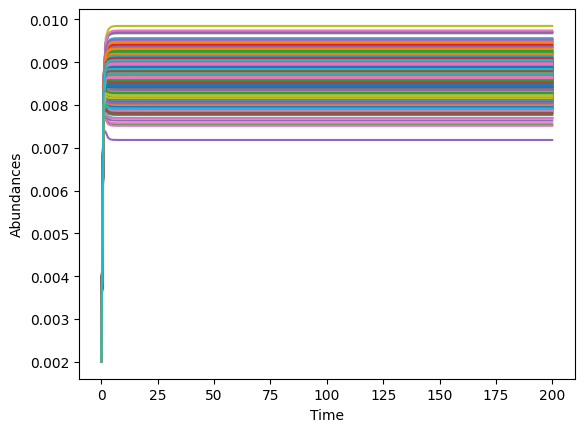

In [42]:
# plot linear abundances

plt.plot(ts, ys)
plt.xlabel("Time")
plt.ylabel("Abundances")
plt.show()

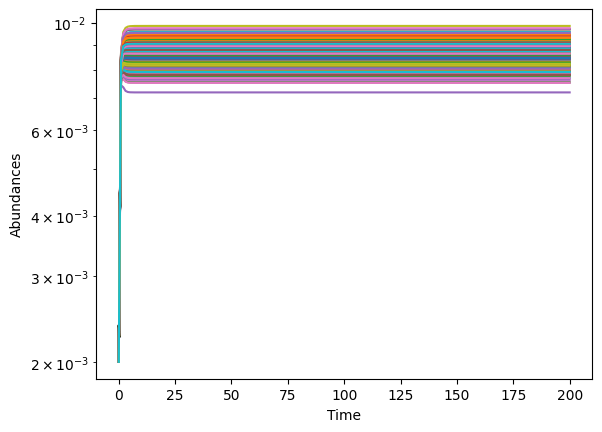

In [43]:
# plot log abundances

plt.plot(ts, ys)
plt.yscale('log')
plt.xlabel("Time")
plt.ylabel("Abundances")
plt.show()

### Notes on solvers and boundary behaviour

The following solvers can be used
- The default `solve` aka `solve_log_RK45` - explicit solver in log-space. Integrating in log-space improves numerical stability/stiffness.
- `solve_RK45` - explicit solver in linear space
- `solve_implicit34`- implicit solver in linear space
- any diffrax adaptive step-size ODE solver can be used; see `make_adaptive_solve`  

If there is positive immigration, there is a limit to how rare a species can become in practise. If there is no immigration, `m=0.`, some species may asymptotically approach 0 abundance, which is problematic:
- Realistically, species should be considered extinct below some small threshold. This prevents unrealistic but mathematically possible recovery from arbitrary low abundance.
- For technical reasons, the best implementation I have found for "extinction" is to freeze abundances once they fall below a `threshold` parameter (by setting the derivative to zero). By default, the solver does not set a threshold. 
- For the log-space solvers (the default), species that crash will eventually cause step sizes to become impractically small. Without immigration `threshold` should always be set
- For linear-space solvers, when species crash machine precision eventually becomes a problem and trajectories look garbled at low abundance, but otherwise not necessarily a problem. Still good to set `threshold` to avoid spurious recovery that's not numerically valid.
- If solvers become very slow, play around with `atol`, `rtol`. If solvers take too many steps there will be an error; then you can increase the `max_steps` argument 

In [24]:
# Deafult solver with a threshold
# Run this and then rerun the plotting cells above

N = 5000
m = 0.
ts, ys = glv.solve(N, dT, r, A, m, y0, rtol=1e-6, atol=1e-9, threshold=1e-12)

In [ ]:
# Linear-space solver without a threshold
# Run this and then rerun the plotting cells above

N = 5000
m = 0.
ts, ys = glv.solve_RK45(N, dT, r, A, m, y0, rtol=1e-6, atol=1e-9)

In [ ]:
# Implicit solver without a threshold
# run this (very slow) and the rerun the plotting cells above
N = 1000
ts, ys = glv.solve_implicit34(N, dT, r, A, m, y0)

## Run a batch of simulations

To run simulations over multiple parameter sets it's much more efficient to vectorize than naively looping. The package makes this efficient and easy.

### Sweep scenario 1
We draw R random matrices from the same statistical ensemble

In [ ]:
R = 10                   # replicates
S = 100
mu = 0.5
sig = 0.3
gam = 0.
diag = 1.
key = 0  

As = glv.gaussian_randmat_ensemble(R, S, mu, sig, gam, diag, key)
rs = jnp.ones(R)
ms = jnp.zeros(R)
y0s = jnp.ones((R, S))/S


### Sweep scenario 2

We have K different sets of statistical parameters, and for each we have R replicates.

Here we will increase μ from 0.2 to 0.8

In [ ]:
R = 10                  # replicates
K = 5                   # parameter cases
B = R * K               # batch size
S = 100

ones = jnp.ones(R*K)
mu = jnp.concat([jnp.linspace(0.2, 0.8, K)]*R)
sig = 0.1 * ones
gam = 0. * ones
diag = 1.
seed1 = 1234
seed2 = jax.random.key(1)

As = glv.gaussian_randmat_ensemble(B, S, mu, sig, gam, diag, seed1)

rs = jax.random.uniform(seed2, (B, S), minval=0.5,maxval=1.5)
y0s = jnp.ones((B,S))/S

### Batch integration (run scenario 1 or 2 first)

In [1]:
N = 100
dT = 1.

ts, ys = glv.jit_batch_solve(N, dT, rs, As, ms, y0s)

NameError: name 'glv' is not defined

Note that the output now has an extra dimension `ys.shape == (B,N,S)` for the batch index.

In [2]:
""" # plot batched abundances
fig,axs=plt.subplots(R,1,figsize=(6,3*R),sharex=True)
for i in range(R):
    axs[i].plot(ts[i], ys[i, :, :])
    axs[i].set_xlabel("Time")
    axs[i].set_ylabel("Abundances")
plt.show() """

' # plot batched abundances\nfig,axs=plt.subplots(R,1,figsize=(6,3*R),sharex=True)\nfor i in range(R):\n    axs[i].plot(ts[i], ys[i, :, :])\n    axs[i].set_xlabel("Time")\n    axs[i].set_ylabel("Abundances")\nplt.show() '

### Biffuraction Diagramm

distance to previous point: 2.7449e+00
m=1.0233e-09, extrema value=5.1453e-03
m=1.0233e-09, extrema value=5.0690e-03
m=1.0233e-09, extrema value=5.1425e-03
m=1.0233e-09, extrema value=4.5116e-03
m=1.0233e-09, extrema value=5.9630e-03
m=1.0233e-09, extrema value=5.2023e-03
m=1.0233e-09, extrema value=5.3771e-03
m=1.0233e-09, extrema value=5.3751e-03
distance to previous point: 9.5148e+00
m=1.0472e-09, extrema value=5.4436e-03
m=1.0472e-09, extrema value=4.7567e-03
m=1.0472e-09, extrema value=5.2414e-03
m=1.0472e-09, extrema value=5.1431e-03
distance to previous point: 7.8273e+00
m=1.0716e-09, extrema value=5.3990e-03
m=1.0716e-09, extrema value=5.2643e-03
m=1.0716e-09, extrema value=5.4376e-03
m=1.0716e-09, extrema value=4.4274e-03
m=1.0716e-09, extrema value=4.7964e-03
m=1.0716e-09, extrema value=4.7943e-03
m=1.0716e-09, extrema value=4.9204e-03
m=1.0716e-09, extrema value=4.3774e-03
m=1.0716e-09, extrema value=4.7051e-03
m=1.0716e-09, extrema value=4.6784e-03
distance to previous poin

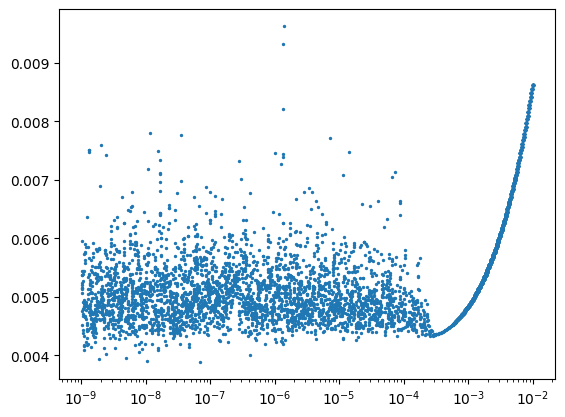

In [44]:
N=100 #Nombre de pas de temps
dT=1# taille du pas detemps
m_min =-9
m_max=-2
m_step=0.01
seuil=1e8 #seuil de distance pour considérer que l'équation converge
nb_esp_test=3 #nombre d'espèces testées pour l'initialisation
y0 = jnp.ones(S)/S  #état initial: un vecteur de taille S   

points=glv.sweep_m_values(N,dT,r,A,y0,m_min,m_max,m_step,seuil,reverse=False)
lm,lval=zip(*points)
plt.scatter(lm,lval,s=2)
plt.xscale('log')
plt.show()


Generating different initial conditions

In [49]:
N=100 #Nombre de pas de temps
dT=1# taille du pas detemps
m_min =-4
m_max=-3.5
m_step=0.0001
seuil=1e4 #seuil de distance pour considérer que l'équation converge
nb_esp_test=3#nombre d'espèces testées pour l'initialisation
y0 = jnp.ones(S)/S  #état initial: un vecteur de taille S   


In [50]:

results=glv.y0_exploration_sweep(N,dT,r,A,y0,m_min,m_max,m_step,seuil,nb_esp_test,reverse=False)


m=1.0000e-04, extrema value=4.3476e-03
m=1.0000e-04, extrema value=4.3175e-03
m=1.0000e-04, extrema value=5.0474e-03
m=1.0000e-04, extrema value=4.9585e-03
distance to previous point: 4.8574e+00
m=1.0002e-04, extrema value=4.8751e-03
m=1.0002e-04, extrema value=5.7553e-03
m=1.0002e-04, extrema value=4.8700e-03
m=1.0002e-04, extrema value=4.8902e-03
m=1.0002e-04, extrema value=4.3822e-03
distance to previous point: 3.3114e+00
m=1.0005e-04, extrema value=5.4551e-03
m=1.0005e-04, extrema value=5.4071e-03
m=1.0005e-04, extrema value=5.4255e-03
distance to previous point: 2.8945e+00
m=1.0007e-04, extrema value=4.4952e-03
m=1.0007e-04, extrema value=4.5957e-03
m=1.0007e-04, extrema value=4.5906e-03
m=1.0007e-04, extrema value=4.8274e-03
m=1.0007e-04, extrema value=4.7350e-03
distance to previous point: 4.2874e+00
m=1.0009e-04, extrema value=4.8774e-03
m=1.0009e-04, extrema value=4.7652e-03
m=1.0009e-04, extrema value=7.4405e-03
m=1.0009e-04, extrema value=4.7727e-03
m=1.0009e-04, extrema val

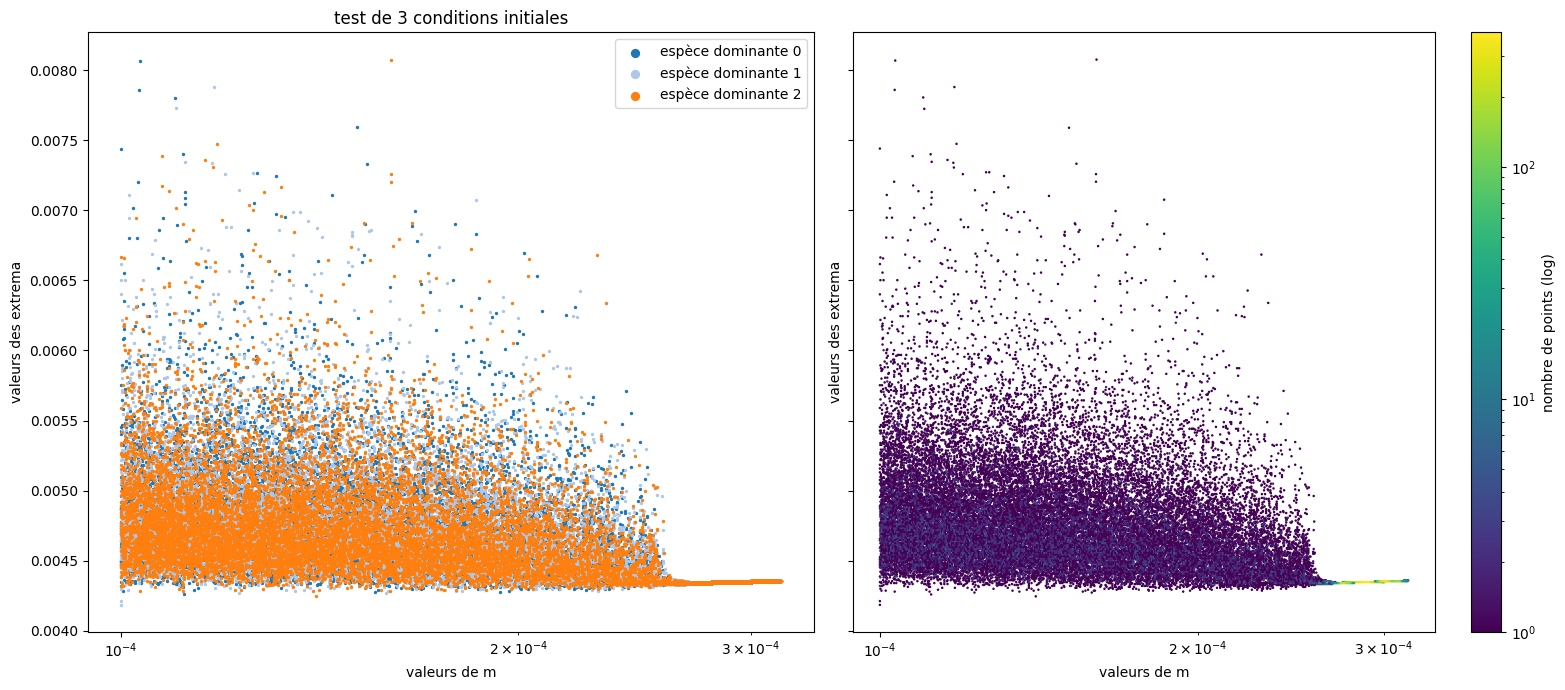

In [51]:
fig,axes=plt.subplots(1,2,layout='tight',sharey=True,figsize=(16,7))
cm1=plt.get_cmap("viridis",len(results))
cm2=plt.get_cmap("tab20")
lm=[]
lval=[]

for idx,esp in enumerate(results):
    lm.extend(esp[0])
    lval.extend(esp[1])
    axes[0].scatter(esp[0],esp[1],s=2,color=cm2(idx),label=f"espèce dominante {idx}")
    
axes[0].set_xlabel('valeurs de m')
axes[0].set_ylabel('valeurs des extrema')
axes[0].set_xscale('log')
axes[0].legend(markerscale=4)
axes[0].set_title(f"test de {nb_esp_test} conditions initiales")

hb=axes[1].hexbin(lm,lval,gridsize=500,cmap="viridis",xscale='log',bins='log',mincnt=1)
axes[1].set_xlabel('valeurs de m')
axes[1].set_ylabel('valeurs des extrema')
fig.colorbar(hb, ax=axes[1], label='nombre de points (log)')

plt.show()

Distinguishing equilibria using Bray Curtis dissimilarity

m=1.0000e-05, extrema value=4.3337e-03
m=1.0000e-05, extrema value=4.3206e-03
m=1.0000e-05, extrema value=5.1557e-03
m=1.0000e-05, extrema value=4.5282e-03
distance to previous point: 5.1718e+00
m=1.0235e-05, extrema value=5.1396e-03
m=1.0235e-05, extrema value=5.0991e-03
m=1.0235e-05, extrema value=5.1190e-03
m=1.0235e-05, extrema value=4.8838e-03
m=1.0235e-05, extrema value=5.8901e-03
distance to previous point: 3.3561e+00
m=1.0476e-05, extrema value=5.3026e-03
m=1.0476e-05, extrema value=5.4044e-03
m=1.0476e-05, extrema value=5.2762e-03
m=1.0476e-05, extrema value=5.2809e-03
m=1.0476e-05, extrema value=4.7133e-03
m=1.0476e-05, extrema value=5.7561e-03
distance to previous point: 5.8600e+00
m=1.0723e-05, extrema value=4.8476e-03
m=1.0723e-05, extrema value=5.3395e-03
m=1.0723e-05, extrema value=5.2006e-03
m=1.0723e-05, extrema value=5.6957e-03
m=1.0723e-05, extrema value=4.6146e-03
m=1.0723e-05, extrema value=4.7579e-03
m=1.0723e-05, extrema value=4.5806e-03
distance to previous poin

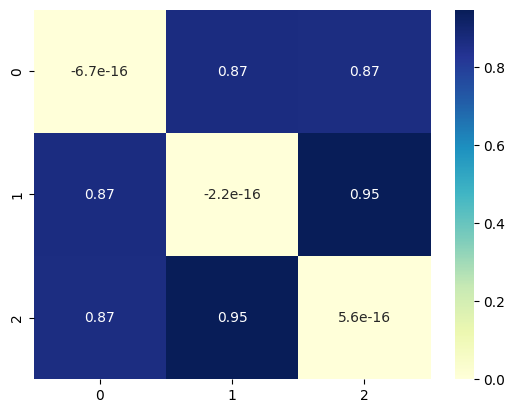

In [ ]:
diss=glv.equilibrium_distinction(N,dT,r,A,y0,m_min,m_max,m_step,seuil,nb_esp_test,reverse=False)
sns.heatmap(diss, annot=True)
plt.show()

Conclusion: over a certain m threshold, all initial conditions arrive to the same equilibrium

PLotting Kullback-leibler divergence

m=1.0000e-05, extrema value=5.2738e-03
m=1.0000e-05, extrema value=5.1688e-03
m=1.0000e-05, extrema value=5.1691e-03
m=1.0000e-05, extrema value=5.0420e-03
distance to previous point: 3.3029e+00
m=1.0235e-05, extrema value=5.8317e-03
m=1.0235e-05, extrema value=4.4090e-03
m=1.0235e-05, extrema value=4.5676e-03
m=1.0235e-05, extrema value=4.5672e-03
m=1.0235e-05, extrema value=5.1538e-03
distance to previous point: 5.9178e+00
m=1.0476e-05, extrema value=4.6358e-03
m=1.0476e-05, extrema value=5.0855e-03
m=1.0476e-05, extrema value=4.9039e-03
m=1.0476e-05, extrema value=5.0412e-03
m=1.0476e-05, extrema value=4.9648e-03
m=1.0476e-05, extrema value=4.9707e-03
m=1.0476e-05, extrema value=4.9299e-03
m=1.0476e-05, extrema value=5.2125e-03
distance to previous point: 6.6502e+00
m=1.0723e-05, extrema value=4.5650e-03
m=1.0723e-05, extrema value=4.8609e-03
m=1.0723e-05, extrema value=4.7894e-03
m=1.0723e-05, extrema value=5.4483e-03
distance to previous point: 7.3194e+00
m=1.0975e-05, extrema val

ValueError: setting an array element with a sequence. The requested array has an inhomogeneous shape after 1 dimensions. The detected shape was (2,) + inhomogeneous part.

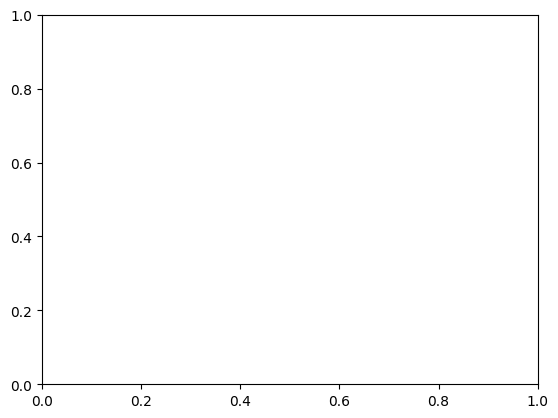

In [ ]:
N=100
dT=1
y0=jnp.ones(S)*1/S
m_min=-5
m_max=-4
m_step=0.01
seuil=5*1e2
m_values = jnp.arange(m_min, m_max, step=m_step)#le vecteur de valeurs des exposant de m
m_values=[10**m for m in m_values]
l=glv.sweep_m_values(N,dT,r,A,y0,m_min,m_max,m_step,seuil,reverse=False,return_yf=True)
plt.plot(m_values,l)
plt.xlabel('Immigration rate (m)')
plt.ylabel('Kullback Leibler divergence')
plt.xscale('log')
plt.yscale('log')
plt.show()

SAD histogramm on snapshots at t=N steps

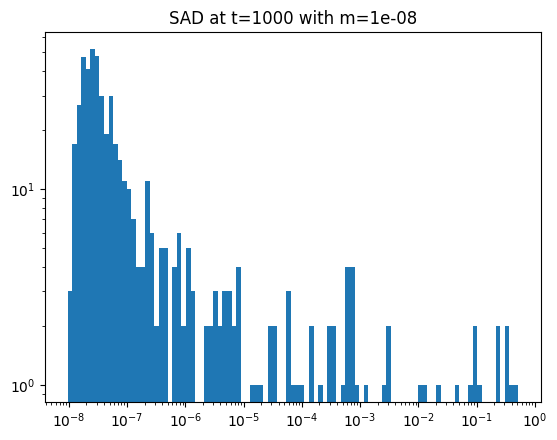

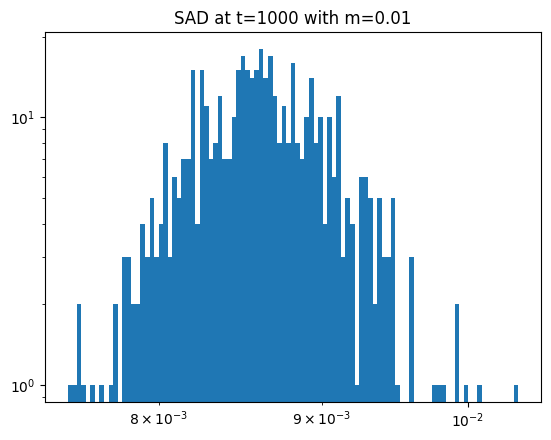

In [ ]:
"""
On regarde les SAD de l'état final avec et sans immigration

"""
N=1000
dT=1
r=1
m1=1e-8
m2=1e-2
y0=jnp.ones(S)*1/S

ts1, ys1 = glv.solve(N, dT, r, A, m1, y0)
ts2, ys2 = glv.solve(N, dT, r, A, m2, y0)

glv.plot_log_hist(ys1[-1],bins=100,m=m1,N=N)
glv.plot_log_hist(ys2[-1], bins=100,m=m2,N=N)



Compparing Abundance Fluctuation Distribution on average species abundances

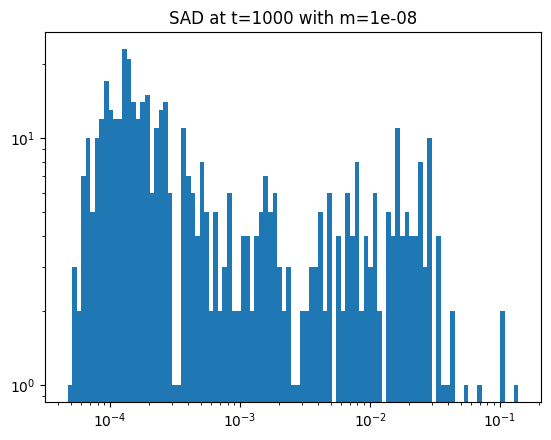

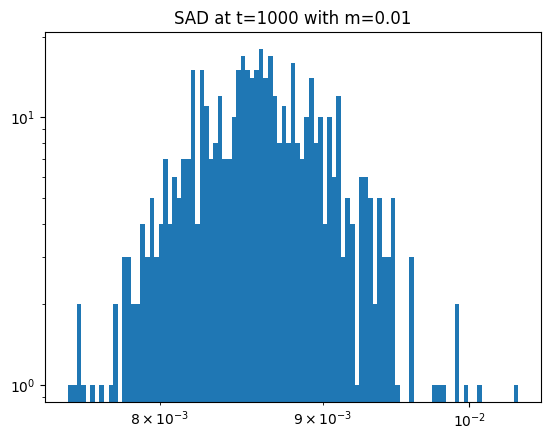

In [ ]:
"""
On regarde les SAD de l'état final avec et sans immigration

"""
N=1000
dT=1
r=1
m1=1e-8
m2=1e-2
y0=jnp.ones(S)*1/S

ts1, ys1 = glv.solve(N, dT, r, A, m1, y0)
ts2, ys2 = glv.solve(N, dT, r, A, m2, y0)

yaverage1=ys1.mean(axis=0)
yaverage2=ys2.mean(axis=0)

glv.plot_log_hist(yaverage1,bins=100,m=m1,N=N)
glv.plot_log_hist(yaverage2, bins=100,m=m2,N=N)

Comparing  with and without immigration using Kl divergence

In [40]:
""" 
On compare la distance de KL entre l'état final avec et sans immigration
"""
N=200 #Nombre de pas de temps
dT=1# taille du pas detemps
m_min =-4
m_max=-2
m_step=0.001
m1=1e-8
seuil=1e8 #seuil de distance pour considérer que l'équation converge
y0 = jnp.ones(S)/S  #état initial: un vecteur de taille S   

t1,y1=glv.solve(N, dT, r, A, m1, y0)
m_values=jnp.logspace(m_min,m_max,int((m_max-m_min)/m_step))

ldist=[]
for m in m_values:
    ts, ys = glv.solve(N, dT, r, A, m, y0)
    ldist.append(glv.kl_divergence(ys[-1],y1[-1]))

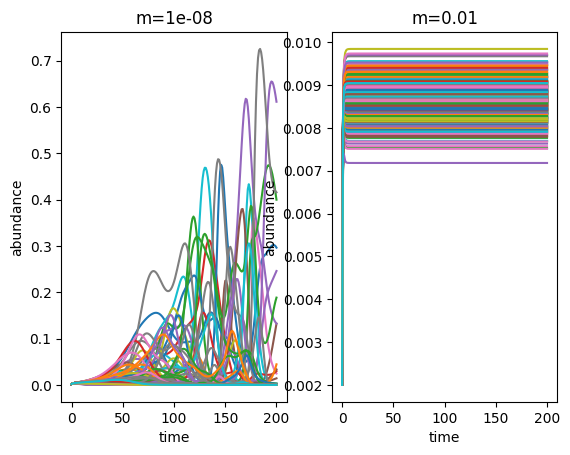

In [41]:
fig,axes=plt.subplots(1,2)
axes[0].plot(t1,y1)
axes[0].set_xlabel('time')
axes[0].set_ylabel('abundance')
axes[0].set_title(f'm={m1}')

axes[1].plot(ts,ys)
axes[1].set_xlabel('time')
axes[1].set_ylabel('abundance')
axes[1].set_title(f'm={m}')

plt.show()

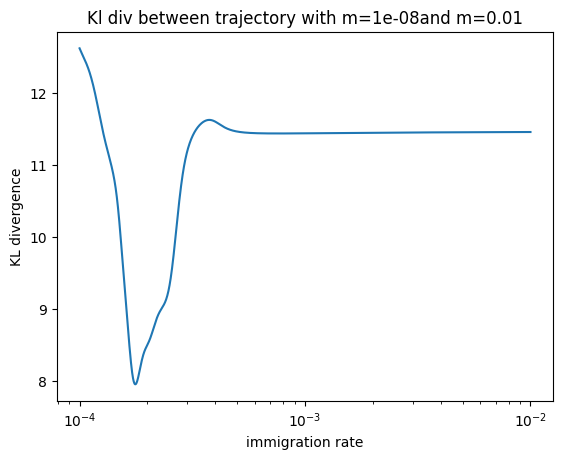

In [ ]:
plt.plot(m_values,ldist)
plt.xscale('log')
plt.xlabel('immigration rate')
plt.ylabel('KL divergence')

plt.title(f'Kl div between trajectory with m={m1}and m={m}')
plt.show()

La différence est minimale en régime chaotique et augmente avec m jusqu'à saturer quand on arrive à l'état d'équilibre. Le point d'inflexion ne coïncide pas avec le moment où on converge. 

Comparing simultaneous equilibria

In [ ]:
""" 
Au préalable, afficher le diagramme de biffurcation avec suffisament de résolution pour pouvoir distinguer les équilibres multiples
prend en argument un m où il y a plusieurs équilibres, et calcule la distance de Bray Curtis entre ces équilibres"""



Retrieving net interaction biases

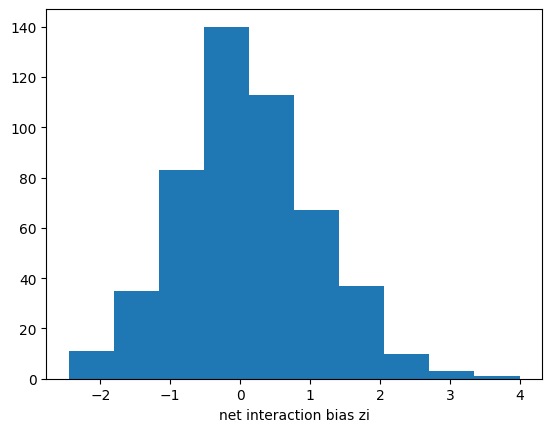

[-1.17721018e-01  5.22185641e-01  1.06732127e+00  1.94341243e-01
 -2.04292647e-01  2.88236490e-01 -1.14315883e+00 -9.30615758e-03
  2.49814821e-01  6.52323308e-01  1.23083459e+00  1.07850373e+00
  1.00456008e+00 -5.48504977e-01  9.33889692e-01 -8.58596457e-02
  8.76082932e-01 -4.38103891e-01 -2.88547923e-01 -5.08240836e-01
 -1.79870208e+00 -8.94062450e-01 -3.73919849e-01  5.62474762e-01
 -3.14813278e-01 -4.12106865e-03  2.76523977e+00 -5.30044336e-03
 -1.81826211e-01 -1.50095418e+00  1.06820027e+00 -9.02536662e-01
 -5.18059130e-01 -1.84648747e+00  1.00554566e+00 -9.24602663e-01
 -1.81200505e-01  2.53497688e-01  2.43038564e+00 -8.01787572e-01
 -9.31275840e-01  3.32050944e-01  4.55850145e-01  4.09074300e-02
  6.49975791e-01  1.23663726e+00 -6.05036241e-01  2.51488828e-02
 -1.15719308e-01  1.71270392e-01  8.16706542e-01 -1.51879696e+00
 -9.79293242e-01 -6.74652482e-02  1.68557789e-01 -3.26764236e-01
 -6.79368499e-01  1.39255533e+00  1.32653662e+00  5.81681677e-01
 -3.92322981e-01  1.98185

In [88]:


lsums=[]
for k in range (S):
    lsums.append(sum(A[k,:]))
lsums=np.array(lsums)
lzi=(lsums- S*mu)*1/(np.sqrt(S)*sig)

plt.hist(lzi)
plt.xlabel('net interaction bias zi')
plt.show()
print(lzi)




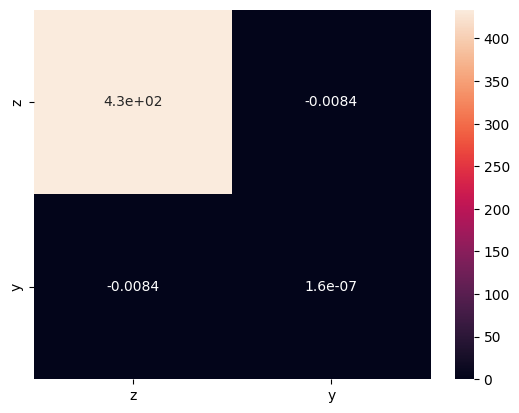

In [ ]:
N=1000
m=1e-2
ts, ys = glv.solve(N, dT, r, A, m, y0)
M=np.array([np.array(lzi),np.array(ys[-1])])
cov=np.cov(M)
sns.heatmap(cov, annot=True,xticklabels=['z','y'],yticklabels=['z','y'])
plt.show()
# pas l'impression qu'il y ait un lien


### Ranked Abundances Diagram

[0.00493448 0.00441144 0.00413394 0.00465668 0.00490992 0.00457512
 0.00598239 0.00477545 0.0046035  0.00435345 0.00402298 0.00418162
 0.00412761 0.00513372 0.00412642 0.00499353 0.00419632 0.00509985
 0.00518769 0.00501922 0.00693457 0.00556369 0.00505625 0.00434795
 0.00519098 0.00479276 0.00326979 0.00478352 0.00483578 0.00619097
 0.00426857 0.0057242  0.00508822 0.00672614 0.00414322 0.00554671
 0.00496742 0.00461228 0.0034141  0.0055661  0.00548856 0.00457674
 0.00450293 0.00467017 0.004424   0.00407824 0.00502526 0.00506896
 0.00481383 0.0046874  0.00423996 0.0066153  0.00538613 0.00486261
 0.00463771 0.00485121 0.00535131 0.00406175 0.00401234 0.0044732
 0.00533979 0.00361388 0.00523749 0.00453346 0.00516924 0.00597521
 0.00407023 0.00409217 0.0059328  0.00426691 0.00488909 0.00489532
 0.00481154 0.00526561 0.00437312 0.00491099 0.00377604 0.00592972
 0.00423643 0.00342547 0.00463451 0.00466847 0.00470738 0.00366715
 0.00469151 0.00412519 0.00455667 0.00504854 0.00762514 0.00472

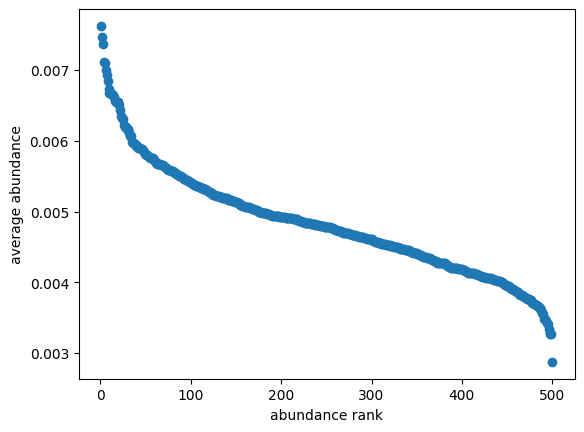

In [97]:
N=1000 #Nombre de pas de temps
dT=1# taille du pas detemps
m1=1e-3
seuil=1e8 #seuil de distance pour considérer que l'équation converge
y0 = jnp.ones(S)/S  #état initial: un vecteur de taille S   
ts,ys=glv.solve(N, dT, r, A, m1, y0)
v=ys.mean(axis=0)
print(v)
vsorted=jnp.sort(v)[::-1]
ranks=jnp.arange(1,S+1)

plt.plot(ranks,vsorted,'o')
plt.xlabel('abundance rank')
plt.ylabel('average abundance')
plt.show()


{0: 305, 1: 151, 2: 92, 3: 216, 4: 291, 5: 196, 6: 465, 7: 246, 8: 199, 9: 140, 10: 61, 11: 101, 12: 91, 13: 350, 14: 88, 15: 323, 16: 106, 17: 346, 18: 361, 19: 327, 20: 493, 21: 419, 22: 335, 23: 139, 24: 363, 25: 254, 26: 1, 27: 250, 28: 272, 29: 472, 30: 122, 31: 441, 32: 344, 33: 491, 34: 94, 35: 418, 36: 315, 37: 204, 38: 5, 39: 420, 40: 410, 41: 197, 42: 174, 43: 221, 44: 155, 45: 77, 46: 328, 47: 340, 48: 262, 49: 224, 50: 117, 51: 485, 52: 397, 53: 278, 54: 210, 55: 275, 56: 391, 57: 71, 58: 58, 59: 167, 60: 390, 61: 13, 62: 374, 63: 185, 64: 359, 65: 464, 66: 74, 67: 80, 68: 461, 69: 119, 70: 284, 71: 286, 72: 261, 73: 378, 74: 144, 75: 293, 76: 29, 77: 460, 78: 116, 79: 6, 80: 209, 81: 220, 82: 232, 83: 17, 84: 226, 85: 87, 86: 191, 87: 334, 88: 499, 89: 235, 90: 229, 91: 313, 92: 430, 93: 63, 94: 180, 95: 405, 96: 186, 97: 159, 98: 290, 99: 81, 100: 427, 101: 241, 102: 345, 103: 364, 104: 70, 105: 316, 106: 388, 107: 32, 108: 387, 109: 225, 110: 107, 111: 66, 112: 79, 113: 

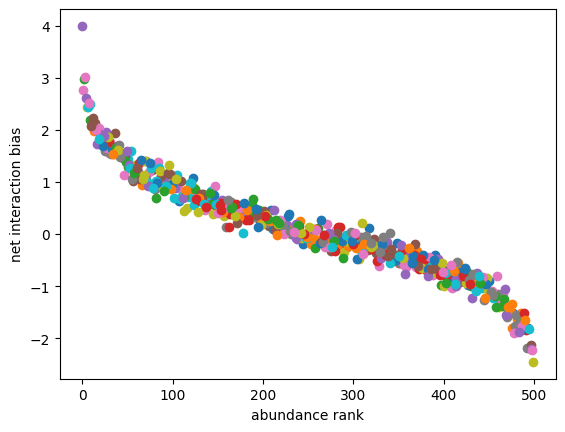

In [98]:
#l'idée est d'avoir un dictionnaire {espi:rang}
ordre=sorted(range(len(v)),key=lambda i:v[i])
rangs={i:rang for rang,i in enumerate(ordre)}
rangs_trie=dict(sorted(rangs.items()))
print(rangs_trie)
for k in range (len(ordre)):
    plt.plot(rangs_trie[k],lzi[k],marker='o')
plt.xlabel('abundance rank')
plt.ylabel('net interaction bias')
plt.show()



Total Abundance 

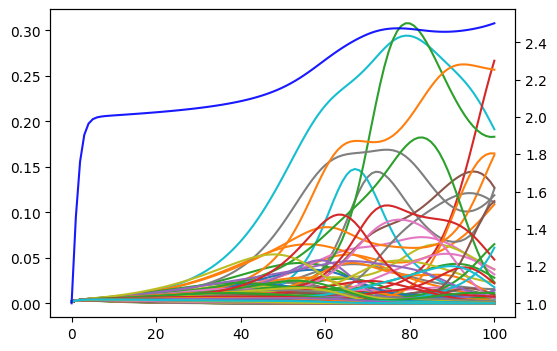

In [ ]:
""" 
On affiche l'abondance totale en bleu dans le profil d'abondances en fonction du temps
"""
somme=jnp.sum(ys,axis=1)
fig,ax1=plt.subplots(figsize=(6,4))
ax1.plot(ts,ys)
ax2=ax1.twinx()
ax2.plot(ts, somme,color='blue',alpha=0.9)
#plt.yscale('log')
plt.show()

Adiabatic mu sweep

In [ ]:
N=1000 #Nombre de pas de temps
dT=1# taille du pas detemps
y0 = jnp.ones(S)/S  #état initial: un vecteur de taille S    
mu_min =0
mu_max=3
mu_step=0.1
mu_values = jnp.arange(mu_min, mu_max, mu_step)
extrema_values_over_lambda=[]#on va mesurer le caractère chaotique de la dynamique en mesurant le nombre d'extrema, comme dans un diagramme d'orbites
for mu in mu_values:
    mu_previous=0                 
    ts,ys = glv.solve_log_RK45(N=N, dT=dT, r=r, A=A+(mu-mu_previous), m=m, y0=y0)#on résout le système pour une certaine valeur de m 
    mu_previous=mu                         
    y0=ys[-1] # Use the last state as the initial condition for the next run 
    mean_abundances = glv.extract_trajectory(ys)#on extrait l'abondance moyenne à chaque pas de temps
    extrema_values = glv.extrema_ammount(mean_abundances)#on compte le nombre d'extrema dans l'abondance moyenne
    extrema_values_over_lambda.append(extrema_values)
    for val in extrema_values:
        print(f"mu={mu:.4e}, extrema value={val:.4e}")
        plt.plot(mu, val, 'o', color='blue',markersize=1)
plt.xlabel('Average interaction (mu)')
plt.ylabel('Extrema values of mean abundance over mu')
#plt.yscale('log')
#plt.xscale('log')
plt.show()


NameError: name 'S' is not defined